# Vježba 6: *Zadatak za samostalan rad*


> Drazen Baric

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel/kernelapp.py", line 739, in start
    self

AttributeError: _ARRAY_API not found

# Zadatak 1

Istražite skup podataka **CIFAR-10** (imate ga u `tensorflow.keras.datasets`).

1. učitajte podatke
2. prikažite uzorak od 20 slučajno odabranih primjera (slika) iz skupa za treniranje zajedno s odgovarajućim labelama

#### Rješenje 1.
> učitavanje podataka i prikaz 20 slučajnih slika

        0/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

     8192/170498071 ━━━━━━━━━━━━━━━━━━━━ 46:00 16us/step

    16384/170498071 ━━━━━━━━━━━━━━━━━━━━ 46:15 16us/step

    24576/170498071 ━━━━━━━━━━━━━━━━━━━━ 45:53 16us/step

    40960/170498071 ━━━━━━━━━━━━━━━━━━━━ 38:28 14us/step

    49152/170498071 ━━━━━━━━━━━━━━━━━━━━ 40:10 14us/step

... (15,780 outputs left out)

170467328/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 7us/step

170483712/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 7us/step

170491904/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 7us/step

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1236s 7us/step


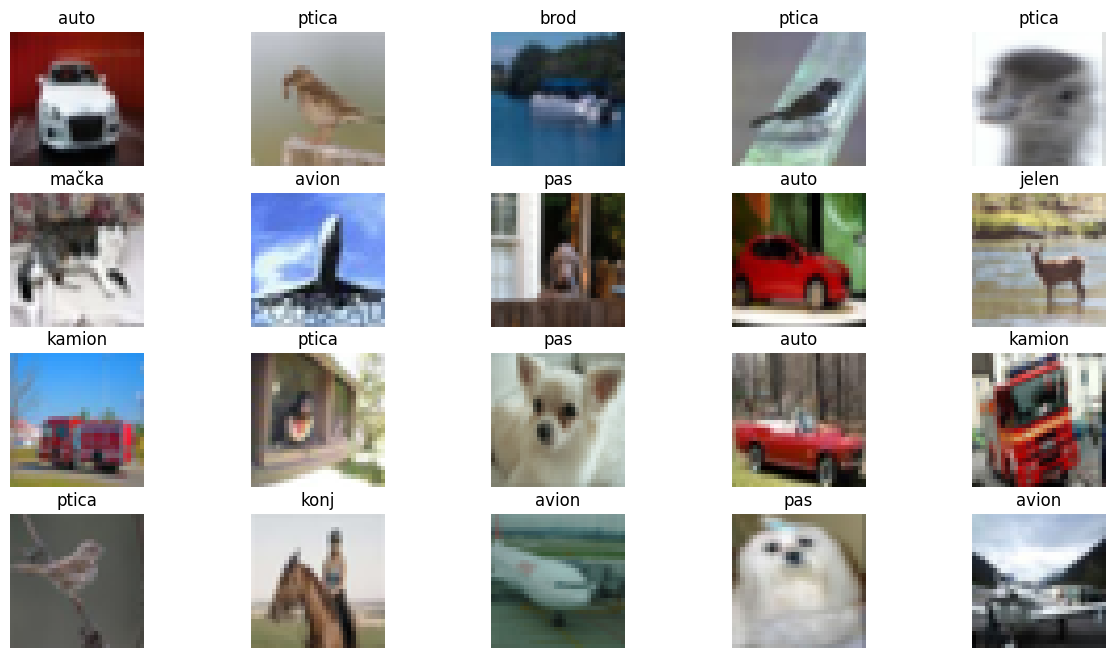

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()
X_train = X_train.astype('float32') / 255.
X_test = X_test.astype('float32') / 255.

klase = ['avion', 'auto', 'ptica', 'mačka', 'jelen', 'pas', 'žaba', 'konj', 'brod', 'kamion']

tf.keras.utils.set_random_seed(7)
plt.figure(figsize=(15, 8))
for k, i in enumerate(np.random.choice(len(X_train), 20, replace=False)):
    plt.subplot(4, 5, k + 1)
    plt.imshow(X_train[i])
    plt.title(klase[y_train[i]])
    plt.axis('off')
plt.show()

# Zadatak 2

Implementirajte **LeNet** konvolucijsku neuronsku mrežu koja će klasificirati slike iz **CIFAR-10** skupa podataka.

![Le-Net](https://www.philschmid.de/static/blog/getting-started-with-cnn-by-calculating-lenet-layer-manually/lenet-5.svg)

> - **s** = `strides`<br>
> - dokumentacija za slojeve: [tf.keras.layers module](https://www.tensorflow.org/api_docs/python/tf/keras/layers)

#### Rješenje 2.
> LeNet-5 (ulaz 32x32x3, konvolucije 5x5 bez paddinga, average pooling 2x2)

In [3]:
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(6, kernel_size=(5, 5), activation='relu'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(16, kernel_size=(5, 5), activation='relu'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(120, activation='relu'),
    tf.keras.layers.Dense(84, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

tf.keras.utils.set_random_seed(7)
povijest = model.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.2, verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


... (25 outputs left out)

Epoch 14/15


625/625 - 4s - 6ms/step - accuracy: 0.6732 - loss: 0.9277 - val_accuracy: 0.5755 - val_loss: 1.2355


Epoch 15/15


625/625 - 4s - 6ms/step - accuracy: 0.6836 - loss: 0.9019 - val_accuracy: 0.5769 - val_loss: 1.2520


# Zadatak 3

##### 3.1. Evaluirajte naučenu mrežu na skupu za *testiranje*.
> Rješenje 3.1.

In [4]:
_, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('Točnost na skupu za testiranje: {:.2f}%'.format(test_acc * 100))

Točnost na skupu za testiranje: 57.04%


3.2. Prikažite slučajan uzorak od 20 pogrešno klasificiranih primjera
> Rješenje 3.2.

Pogrešno razvrstanih slika: 4296/10000


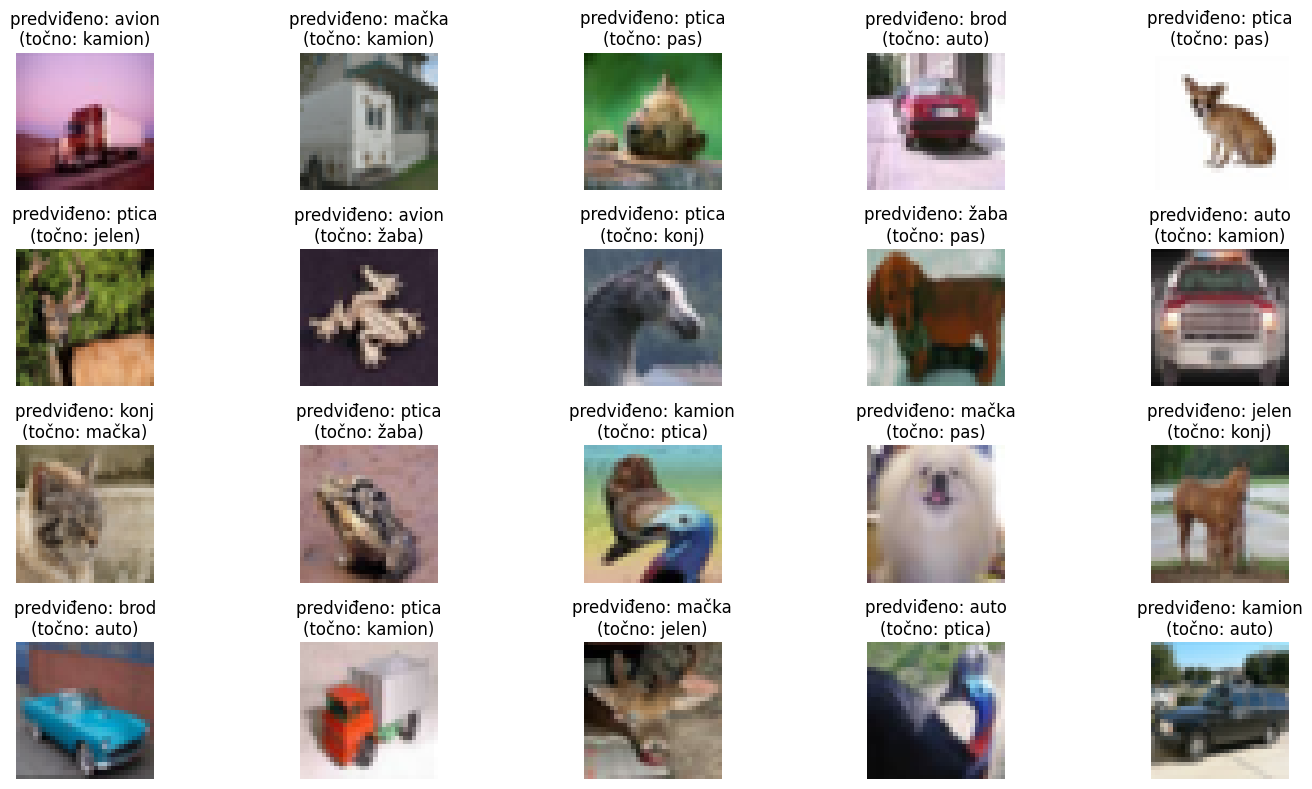

In [5]:
y_hat = model.predict(X_test, verbose=0).argmax(axis=1)
pogresni = np.where(y_hat != y_test)[0]
print('Pogrešno razvrstanih slika: {}/{}'.format(len(pogresni), len(y_test)))

plt.figure(figsize=(15, 8))
for k, i in enumerate(np.random.choice(pogresni, 20, replace=False)):
    plt.subplot(4, 5, k + 1)
    plt.imshow(X_test[i])
    plt.title('predviđeno: {}\n(točno: {})'.format(klase[y_hat[i]], klase[y_test[i]]))
    plt.axis('off')
plt.tight_layout()
plt.show()